<a href="https://colab.research.google.com/github/nilesh-r-dev/TNS_T170800502_AIML/blob/main/tns_day_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Unsupervised Machine Learning Project**

In [1]:
!pip install -q kaggle pandas openpyxl scikit-learn seaborn matplotlib

from google.colab import files
import os
import shutil
import glob
import zipfile
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

uploaded = files.upload()
json_file = next((f for f in uploaded if f.endswith('.json')), None)

if json_file is None:
    raise FileNotFoundError("Upload your kaggle.json file")

os.makedirs('/root/.kaggle', exist_ok=True)
shutil.copy(json_file, '/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json', 0o600)

!kaggle datasets download -d joebeachcapital/customer-segmentation -p /content/customer_data

for z in glob.glob('/content/customer_data/*.zip'):
    with zipfile.ZipFile(z, 'r') as zip_ref:
        zip_ref.extractall('/content/customer_data/extracted')

print("Dataset downloaded successfully")

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/joebeachcapital/customer-segmentation
License(s): DbCL-1.0
100% 1.55k/1.55k [00:00<00:00, 2.88MB/s]

Dataset downloaded successfully


In [2]:
csv_files = glob.glob('/content/customer_data/**/*.csv', recursive=True)
excel_files = glob.glob('/content/customer_data/**/*.xlsx', recursive=True)

if csv_files:
    df = pd.read_csv(csv_files[0])
elif excel_files:
    df = pd.read_excel(excel_files[0])
else:
    raise FileNotFoundError("No CSV or Excel file found. Check the downloaded files.")

df.columns = df.columns.str.strip()

print(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
Shape: (200, 5)
Columns: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


In [3]:
print(df.info())
print(df.describe(include='all'))
print("Missing values:")
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None
        CustomerID  Gender         Age  Annual Income (k$)  \
count   200.000000     200  200.000000          200.000000   
unique         NaN       2         NaN                 NaN   
top            NaN  Female         NaN                 NaN   
freq           NaN     112         NaN                 NaN   
mean    100.500000     NaN   38.850000           60.560000   
std      57.879185     NaN   13.969007           26.264721   
min       1.000000     NaN   18.000000     

In [4]:
df = df.drop_duplicates().copy()

for col in df.columns:
    if df[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            mode = df[col].mode()
            if not mode.empty:
                df[col] = df[col].fillna(mode[0])

print("Cleaned shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())

Cleaned shape: (200, 5)
Total missing values: 0


In [5]:
from sklearn.preprocessing import LabelEncoder

df['Gender'] = LabelEncoder().fit_transform(df['Gender'])

print(df.head())
print(df.dtypes)

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1       1   19                  15                      39
1           2       1   21                  15                      81
2           3       0   20                  16                       6
3           4       0   23                  16                      77
4           5       0   31                  17                      40
CustomerID                int64
Gender                    int64
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object


In [6]:
print(df.dtypes)
print(df.head())

CustomerID                int64
Gender                    int64
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1       1   19                  15                      39
1           2       1   21                  15                      81
2           3       0   20                  16                       6
3           4       0   23                  16                      77
4           5       0   31                  17                      40


In [7]:
df['Age_Category'] = pd.cut(
    df['Age'],
    bins=[0, 25, 35, 50, 100],
    labels=['Young', 'Adult', 'Middle-Aged', 'Senior']
)

print(df[['Age', 'Age_Category']].head(10))

   Age Age_Category
0   19        Young
1   21        Young
2   20        Young
3   23        Young
4   31        Adult
5   22        Young
6   35        Adult
7   23        Young
8   64       Senior
9   30        Adult


In [8]:
df['Income_Category'] = pd.cut(
    df['Annual Income (k$)'],
    bins=[0, 30, 60, 90, float('inf')],
    labels=['Low Income', 'Medium Income', 'High Income', 'Very High Income']
)

print(df[['Annual Income (k$)', 'Income_Category']].head(10))

   Annual Income (k$) Income_Category
0                  15      Low Income
1                  15      Low Income
2                  16      Low Income
3                  16      Low Income
4                  17      Low Income
5                  17      Low Income
6                  18      Low Income
7                  18      Low Income
8                  19      Low Income
9                  19      Low Income


In [9]:
df['Spending_Category'] = pd.cut(
    df['Spending Score (1-100)'],
    bins=[0, 40, 70, 100],
    labels=['Low Spending', 'Medium Spending', 'High Spending'],
    include_lowest=True
)

print(df[['Spending Score (1-100)', 'Spending_Category']].head(10))

   Spending Score (1-100) Spending_Category
0                      39      Low Spending
1                      81     High Spending
2                       6      Low Spending
3                      77     High Spending
4                      40      Low Spending
5                      76     High Spending
6                       6      Low Spending
7                      94     High Spending
8                       3      Low Spending
9                      72     High Spending


In [10]:
display(df.head(10))

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Age_Category,Income_Category,Spending_Category
0,1,1,19,15,39,Young,Low Income,Low Spending
1,2,1,21,15,81,Young,Low Income,High Spending
2,3,0,20,16,6,Young,Low Income,Low Spending
3,4,0,23,16,77,Young,Low Income,High Spending
4,5,0,31,17,40,Adult,Low Income,Low Spending
5,6,0,22,17,76,Young,Low Income,High Spending
6,7,0,35,18,6,Adult,Low Income,Low Spending
7,8,0,23,18,94,Young,Low Income,High Spending
8,9,1,64,19,3,Senior,Low Income,Low Spending
9,10,0,30,19,72,Adult,Low Income,High Spending


In [11]:
df.tail()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Age_Category,Income_Category,Spending_Category
195,196,0,35,120,79,Adult,Very High Income,High Spending
196,197,0,45,126,28,Middle-Aged,Very High Income,Low Spending
197,198,1,32,126,74,Adult,Very High Income,High Spending
198,199,1,32,137,18,Adult,Very High Income,Low Spending
199,200,1,30,137,83,Adult,Very High Income,High Spending


In [12]:
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Shape: (200, 8)
Columns: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Age_Category', 'Income_Category', 'Spending_Category']


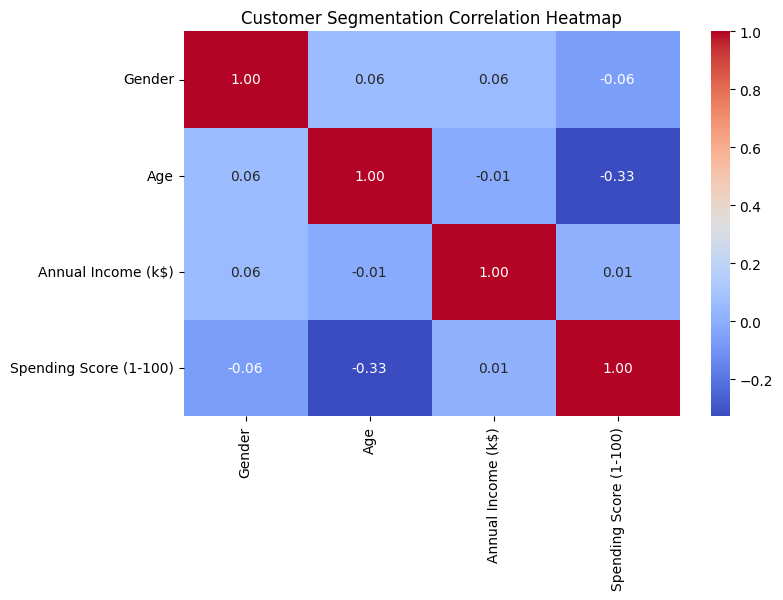

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

num_df = df.select_dtypes(include='number').drop(
    columns=['CustomerID'], errors='ignore'
)

plt.figure(figsize=(8, 5))
sns.heatmap(num_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Customer Segmentation Correlation Heatmap')
plt.show()

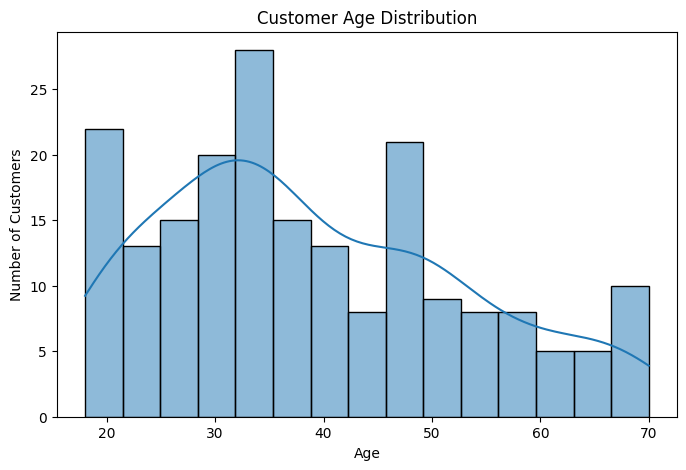

In [14]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Age', bins=15, kde=True)
plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.show()

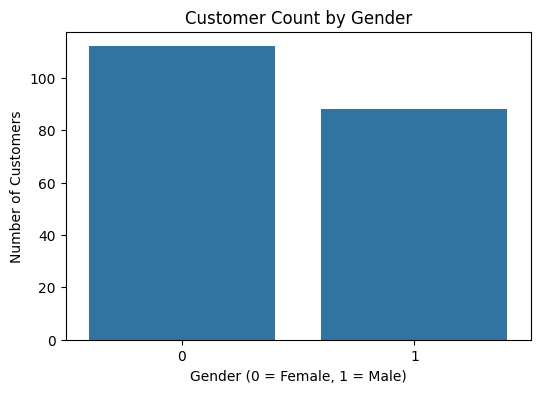

In [15]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Gender')
plt.title('Customer Count by Gender')
plt.xlabel('Gender (0 = Female, 1 = Male)')
plt.ylabel('Number of Customers')
plt.show()

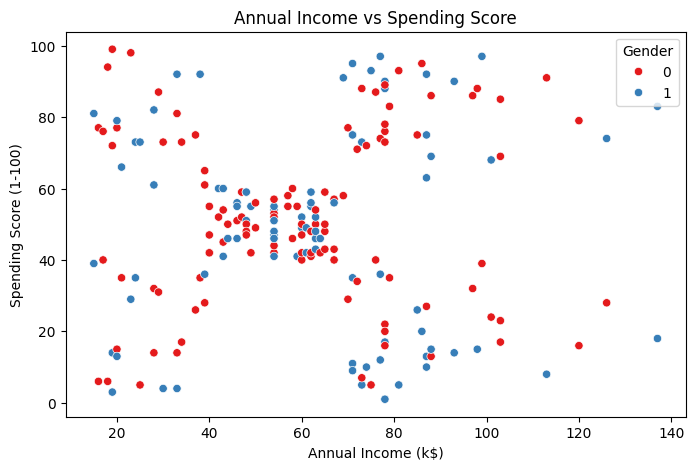

In [16]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Gender',
    palette='Set1'
)
plt.title('Annual Income vs Spending Score')
plt.show()

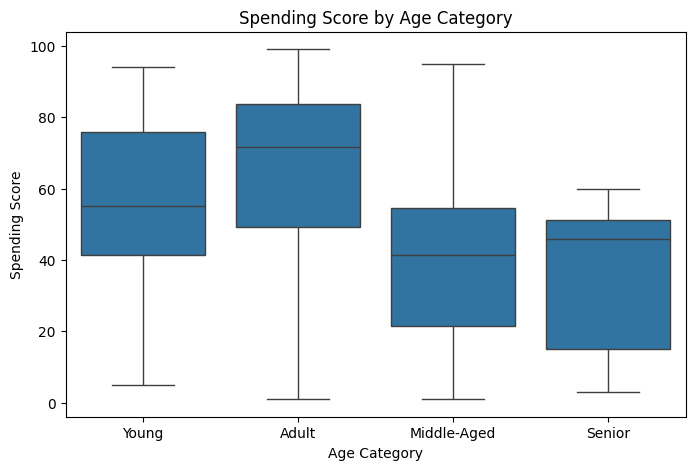

In [17]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Age_Category', y='Spending Score (1-100)')
plt.title('Spending Score by Age Category')
plt.xlabel('Age Category')
plt.ylabel('Spending Score')
plt.show()

In [18]:
df['Age_Category'] = pd.cut(
    df['Age'],
    bins=[0, 25, 35, 50, 100],
    labels=['Young', 'Adult', 'Middle-Aged', 'Senior']
)

In [20]:
# Identify numerical columns
numerical_columns = df.select_dtypes(include='number').columns

# Detect outliers using IQR
for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print(col, ":", len(outliers), "outliers")

CustomerID : 0 outliers
Gender : 0 outliers
Age : 0 outliers
Annual Income (k$) : 2 outliers
Spending Score (1-100) : 0 outliers


In [21]:
# Select numerical columns except CustomerID
numerical_columns = df.select_dtypes(include='number').columns.drop(
    'CustomerID', errors='ignore'
)

In [24]:
# Import LabelEncoder
from sklearn.preprocessing import LabelEncoder

# Select categorical columns
categorical_columns = df.select_dtypes(include=['object', 'category']).columns

# Convert categorical data into numerical data
encoder = LabelEncoder()

for col in categorical_columns:
    df[col] = encoder.fit_transform(df[col])

# Display the result
print(df.head())

# Check data types
print(df.dtypes)

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1       1   19                  15                      39   
1           2       1   21                  15                      81   
2           3       0   20                  16                       6   
3           4       0   23                  16                      77   
4           5       0   31                  17                      40   

   Age_Category  Income_Category  Spending_Category  
0             3                1                  1  
1             3                1                  0  
2             3                1                  1  
3             3                1                  0  
4             0                1                  1  
CustomerID                int64
Gender                    int64
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
Age_Category              int64
Income_Category           int64
Spendin

In [25]:
# Encode only Gender
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
df['Gender'] = encoder.fit_transform(df['Gender'])

print(df.head())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1       1   19                  15                      39   
1           2       1   21                  15                      81   
2           3       0   20                  16                       6   
3           4       0   23                  16                      77   
4           5       0   31                  17                      40   

   Age_Category  Income_Category  Spending_Category  
0             3                1                  1  
1             3                1                  0  
2             3                1                  1  
3             3                1                  0  
4             0                1                  1  


In [26]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Age_Category,Income_Category,Spending_Category
0,1,1,19,15,39,3,1,1
1,2,1,21,15,81,3,1,0
2,3,0,20,16,6,3,1,1
3,4,0,23,16,77,3,1,0
4,5,0,31,17,40,0,1,1


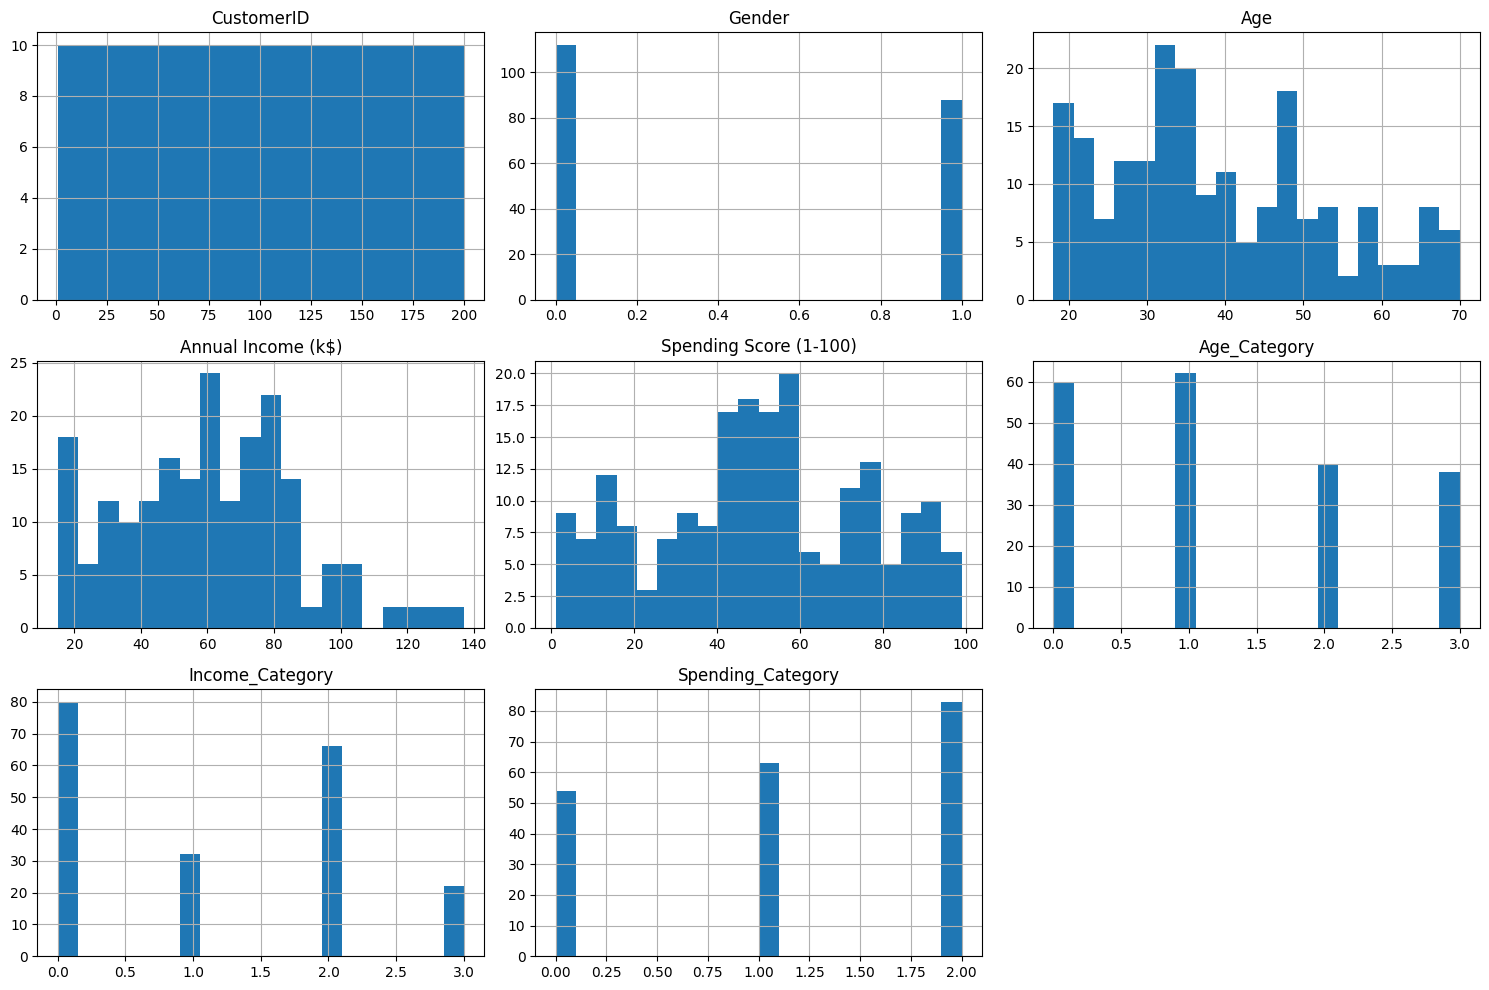

In [27]:

df.hist(figsize=(15,10), bins=20)

plt.tight_layout()
plt.show()

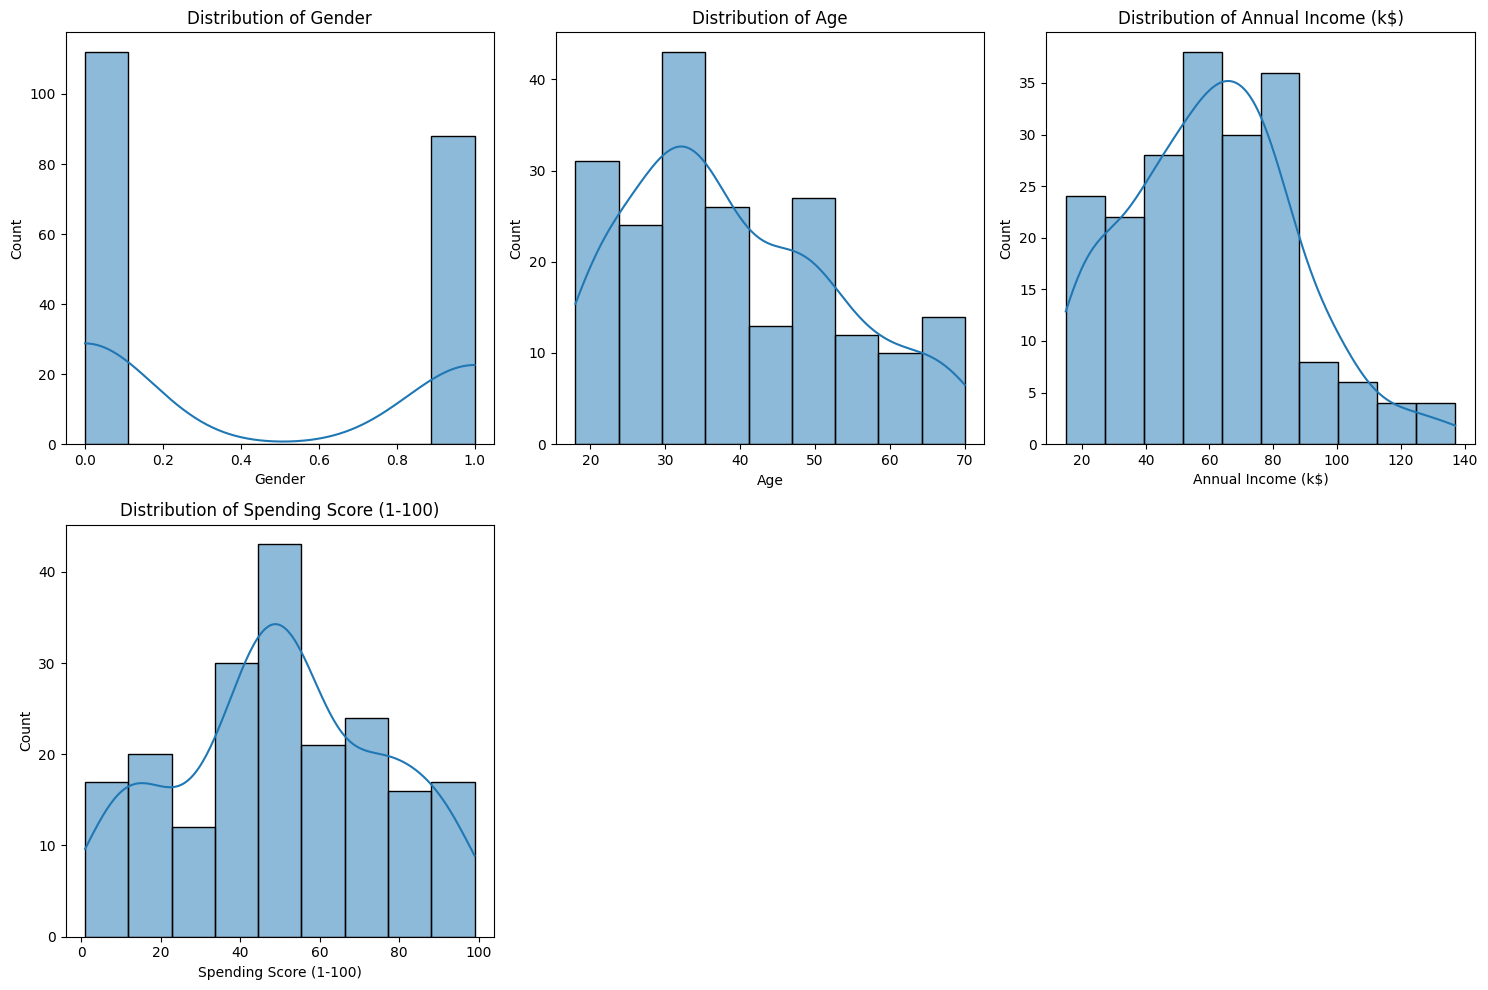

In [28]:
plt.figure(figsize=(15,10))

for i, col in enumerate(numerical_columns):

    plt.subplot(2,3,i+1)
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

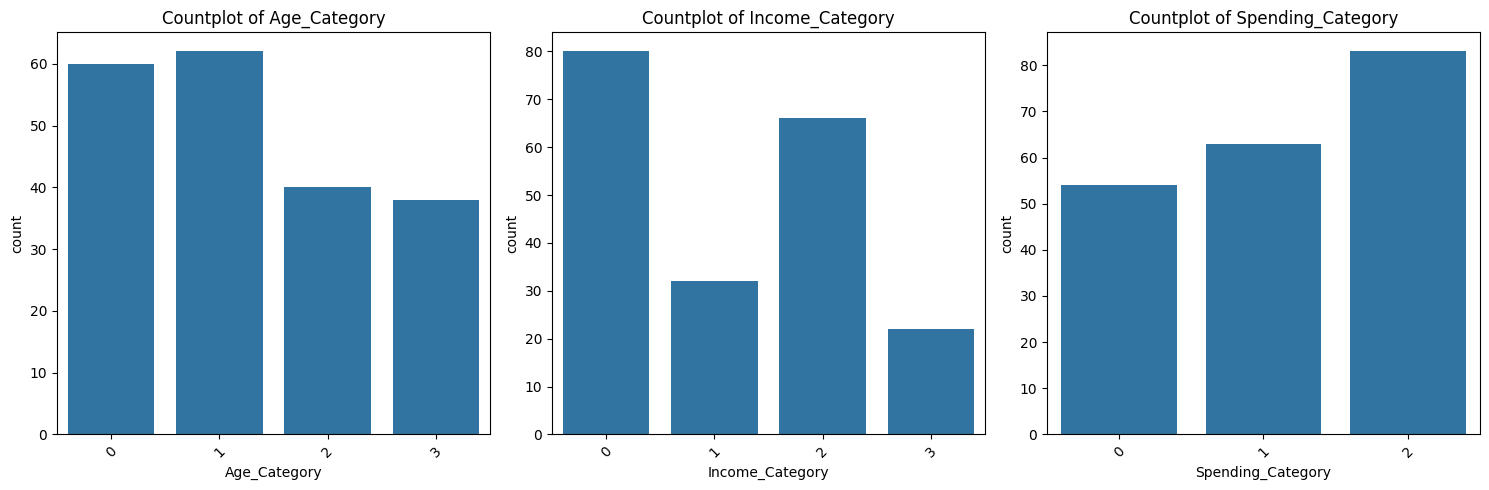

In [30]:
# Countplots for categorical columns
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 5))

for i, col in enumerate(categorical_columns):
    plt.subplot(1, len(categorical_columns), i + 1)
    sns.countplot(data=df, x=col)
    plt.title(f'Countplot of {col}')
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

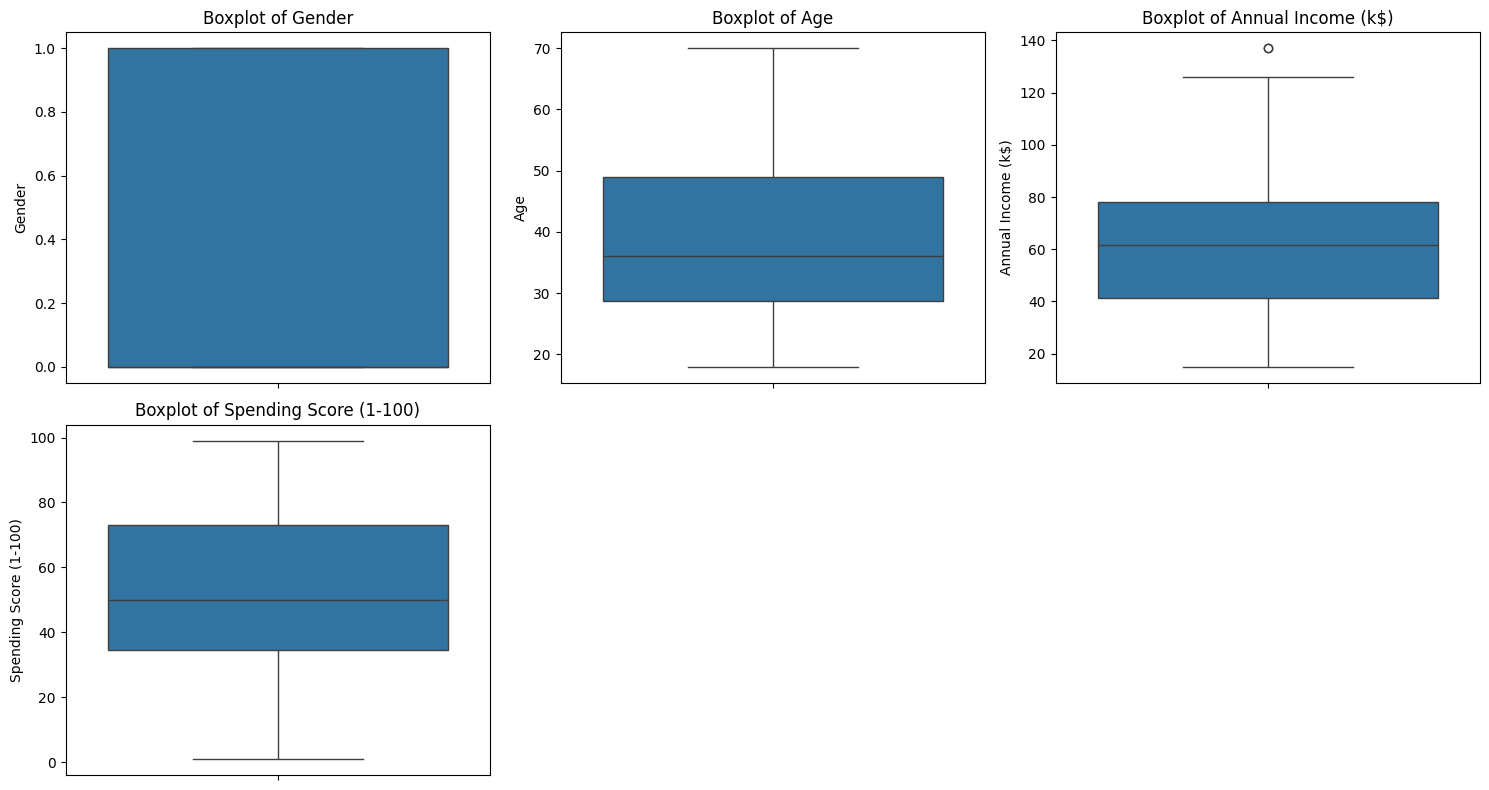

In [31]:

plt.figure(figsize=(15,8))

for i, col in enumerate(numerical_columns):

    plt.subplot(2,3,i+1)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

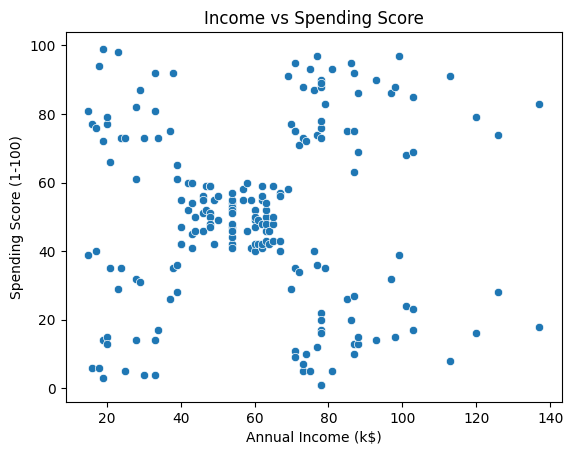

In [32]:
sns.scatterplot(
    x=df['Annual Income (k$)'],
    y=df['Spending Score (1-100)']
)

plt.title('Income vs Spending Score')
plt.show()

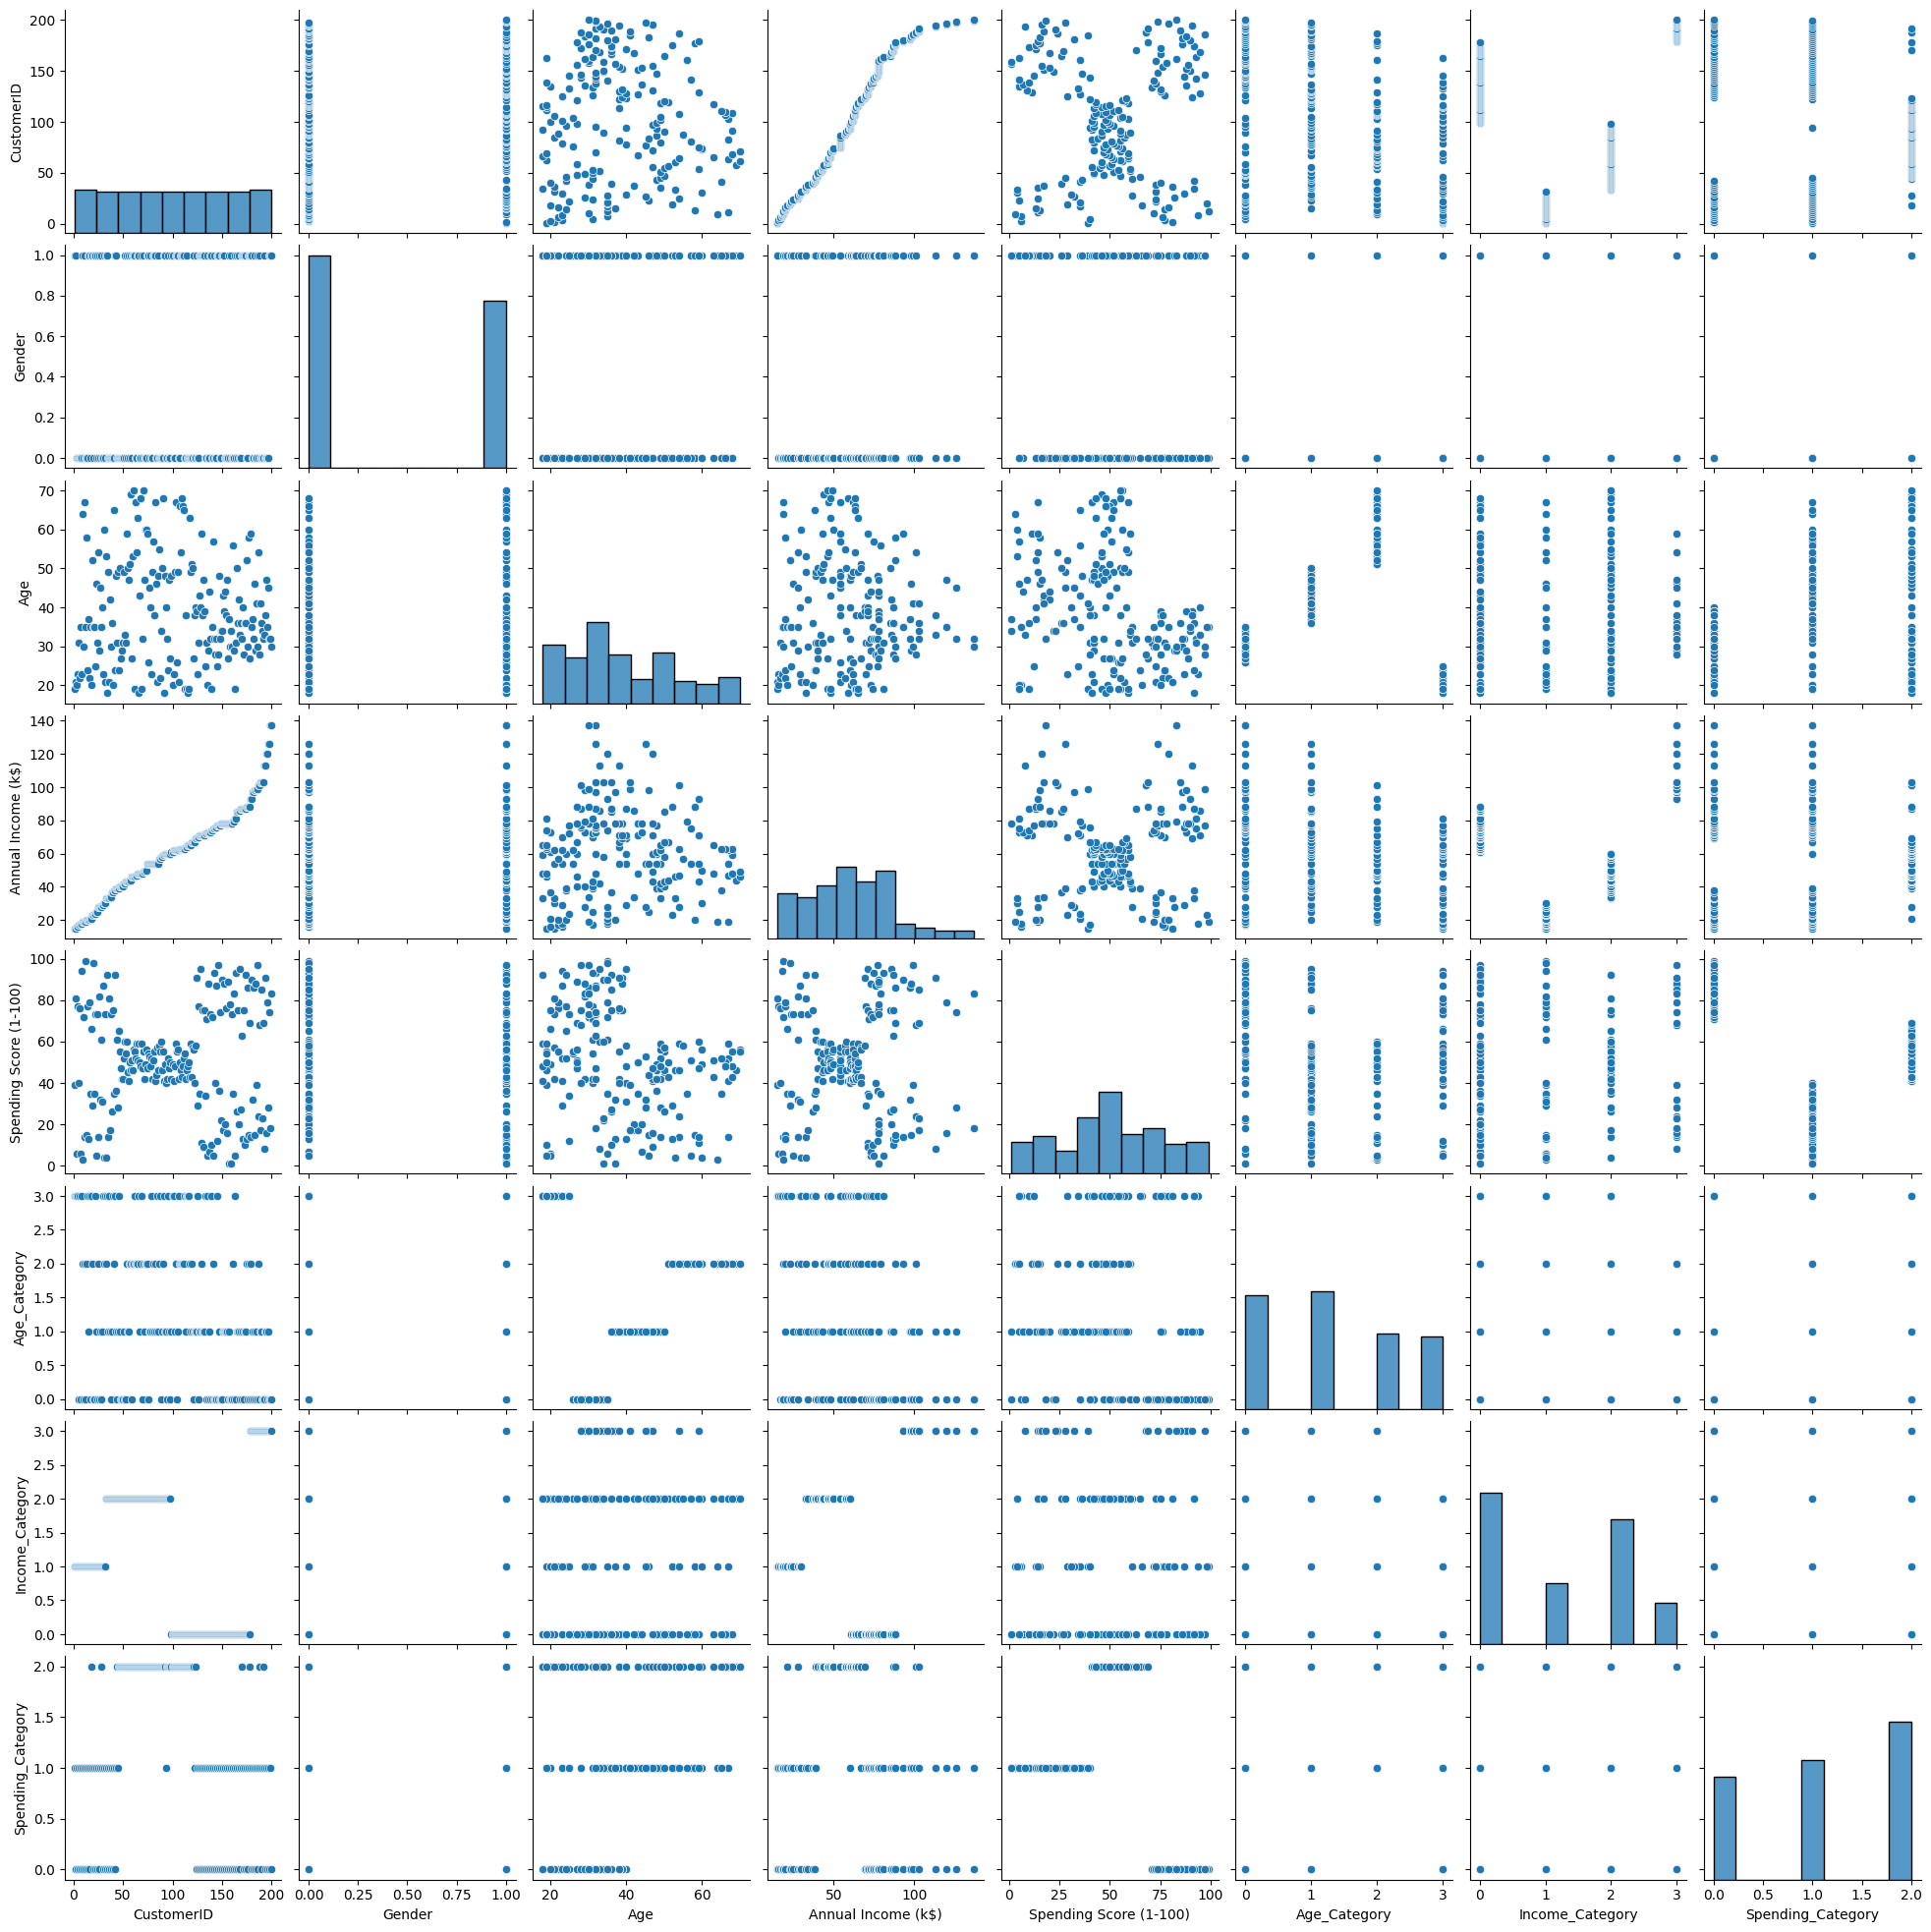

In [33]:
sns.pairplot(df)

plt.show()

In [34]:
correlation_matrix = df.corr()

correlation_matrix

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Age_Category,Income_Category,Spending_Category
CustomerID,1.000000,0.057400,-0.026763,0.977548,0.013835,-0.323624,-0.115933,-0.183602
Gender,0.057400,1.000000,0.060867,0.056410,-0.058109,0.096001,-0.095912,0.027690
Age,-0.026763,0.060867,1.000000,-0.012398,-0.327227,-0.004820,0.080227,0.318982
Annual Income (k$),0.977548,0.056410,-0.012398,1.000000,0.009903,-0.325570,0.031214,-0.147610
Spending Score (1-100),0.013835,-0.058109,-0.327227,0.009903,1.000000,-0.179141,0.018302,-0.395626
Age_Category,-0.323624,0.096001,-0.004820,-0.325570,-0.179141,1.000000,-0.044657,0.208185
Income_Category,-0.115933,-0.095912,0.080227,0.031214,0.018302,-0.044657,1.000000,0.169841
Spending_Category,-0.183602,0.027690,0.318982,-0.147610,-0.395626,0.208185,0.169841,1.000000


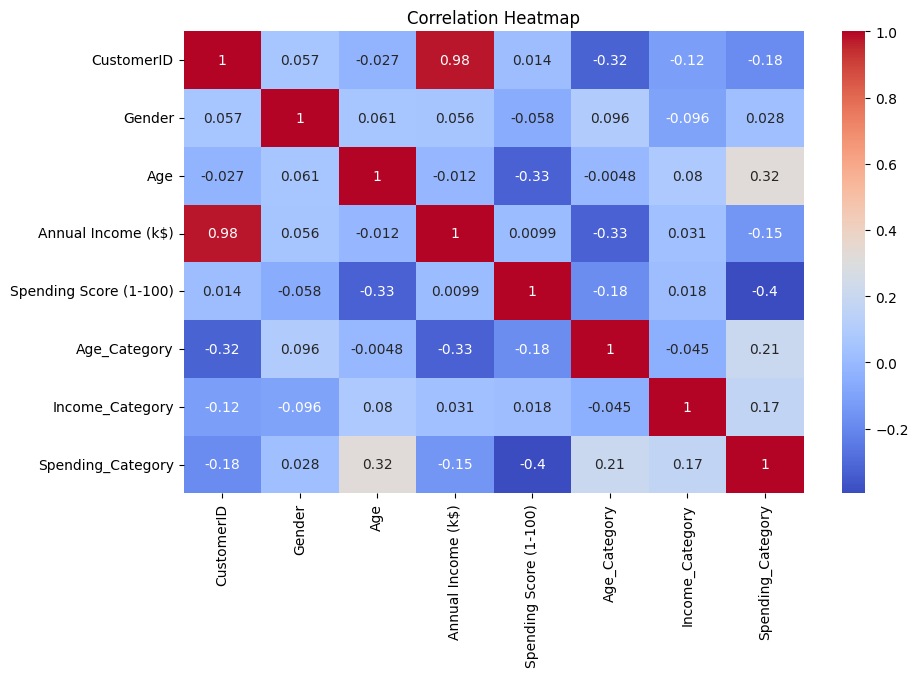

In [35]:
plt.figure(figsize=(10,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')

plt.show()

In [36]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)', 'Age_Category', 'Income_Category',
       'Spending_Category'],
      dtype='object')

In [37]:
if 'CustomerID' in df.columns:
    df.drop('CustomerID', axis=1, inplace=True)

print("Irrelevant columns removed successfully!")

Irrelevant columns removed successfully!


In [38]:
df['Age_Group'] = pd.cut(
    df['Age'],
    bins=[0, 25, 40, 60, 100],
    labels=['Young', 'Adult', 'Middle_Age', 'Senior']
)

df.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100),Age_Category,Income_Category,Spending_Category,Age_Group
0,1,19,15,39,3,1,1,Young
1,1,21,15,81,3,1,0,Young
2,0,20,16,6,3,1,1,Young
3,0,23,16,77,3,1,0,Young
4,0,31,17,40,0,1,1,Adult


In [39]:
df['Income_Category'] = pd.cut(
    df['Annual Income (k$)'],
    bins=[0, 40, 70, 150],
    labels=['Low', 'Medium', 'High']
)

df.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100),Age_Category,Income_Category,Spending_Category,Age_Group
0,1,19,15,39,3,Low,1,Young
1,1,21,15,81,3,Low,0,Young
2,0,20,16,6,3,Low,1,Young
3,0,23,16,77,3,Low,0,Young
4,0,31,17,40,0,Low,1,Adult


In [40]:
df['Spending_Category'] = pd.cut(
    df['Spending Score (1-100)'],
    bins=[0, 40, 70, 100],
    labels=['Low', 'Medium', 'High']
)

df.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100),Age_Category,Income_Category,Spending_Category,Age_Group
0,1,19,15,39,3,Low,Low,Young
1,1,21,15,81,3,Low,High,Young
2,0,20,16,6,3,Low,Low,Young
3,0,23,16,77,3,Low,High,Young
4,0,31,17,40,0,Low,Low,Adult


In [41]:

from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

new_categorical_columns = [
    'Age_Group',
    'Income_Category',
    'Spending_Category'
]

for col in new_categorical_columns:
    df[col] = encoder.fit_transform(df[col])

print("New categorical features encoded successfully!")

New categorical features encoded successfully!


In [42]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_data = scaler.fit_transform(df)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


In [43]:
scaled_data.shape

(200, 8)

In [44]:
scaled_df = pd.DataFrame(
    scaled_data,
    columns=df.columns
)

scaled_df.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100),Age_Category,Income_Category,Spending_Category,Age_Group
0,1.128152,-1.424569,-1.738999,-0.434801,1.582316,-0.011548,-0.177948,1.739600
1,1.128152,-1.281035,-1.738999,1.195704,1.582316,-0.011548,-1.405172,1.739600
2,-0.886405,-1.352802,-1.700830,-1.715913,1.582316,-0.011548,-0.177948,1.739600
3,-0.886405,-1.137502,-1.700830,1.040418,1.582316,-0.011548,-1.405172,1.739600
4,-0.886405,-0.563369,-1.662660,-0.395980,-1.177537,-0.011548,-0.177948,-0.929863


In [45]:
scaled_df.describe()

,Gender,Age,Annual Income (k$),Spending Score (1-100),Age_Category,Income_Category,Spending_Category,Age_Group
count,2.000000e+02,2.000000e+02,2.000000e+02,2.000000e+02,2.000000e+02,2.000000e+02,2.000000e+02,2.000000e+02
mean,3.108624e-17,-1.021405e-16,-2.131628e-16,-1.465494e-16,-3.552714e-17,-3.552714e-17,3.552714e-17,3.552714e-17
std,1.002509e+00,1.002509e+00,1.002509e+00,1.002509e+00,1.002509e+00,1.002509e+00,1.002509e+00,1.002509e+00
min,-8.864053e-01,-1.496335e+00,-1.738999e+00,-1.910021e+00,-1.177537e+00,-1.166325e+00,-1.405172e+00,-9.298629e-01
25%,-8.864053e-01,-7.248436e-01,-7.275093e-01,-5.997931e-01,-1.177537e+00,-1.166325e+00,-1.405172e+00,-9.298629e-01
50%,-8.864053e-01,-2.045351e-01,3.587926e-02,-7.764312e-03,-2.575863e-01,-1.154778e-02,-1.779476e-01,-4.004194e-02
75%,1.128152e+00,7.284319e-01,6.656748e-01,8.851316e-01,6.623648e-01,1.143230e+00,1.049277e+00,8.497790e-01
max,1.128152e+00,2.235532e+00,2.917671e+00,1.894492e+00,1.582316e+00,1.143230e+00,1.049277e+00,1.739600e+00


In [46]:
inertia_values = []

K_range = range(1, 11)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42
    )

    kmeans.fit(scaled_data)

    inertia_values.append(kmeans.inertia_)

NameError: name 'KMeans' is not defined

In [47]:
# Import KMeans
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Define the range of K values
K_range = range(1, 11)

# Store WCSS values
wcss = []

# Calculate WCSS for each K
for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Method graph
plt.plot(K_range, wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.xticks(K_range)
plt.grid(True)
plt.show()

NameError: name 'X_scaled' is not defined

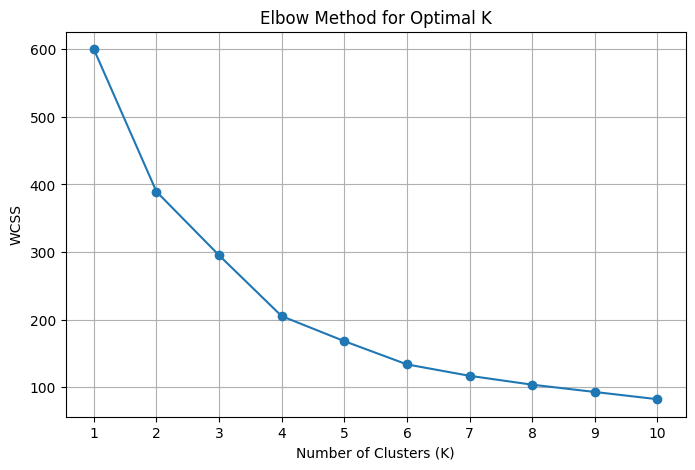

In [48]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Select numerical columns for clustering
X = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

# Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Elbow Method
K_range = range(1, 11)
wcss = []

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow graph
plt.figure(figsize=(8, 5))
plt.plot(K_range, wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method for Optimal K')
plt.xticks(K_range)
plt.grid(True)
plt.show()

K = 2, Silhouette Score = 0.335
K = 3, Silhouette Score = 0.358
K = 4, Silhouette Score = 0.404
K = 5, Silhouette Score = 0.417
K = 6, Silhouette Score = 0.428
K = 7, Silhouette Score = 0.417
K = 8, Silhouette Score = 0.408
K = 9, Silhouette Score = 0.418
K = 10, Silhouette Score = 0.407


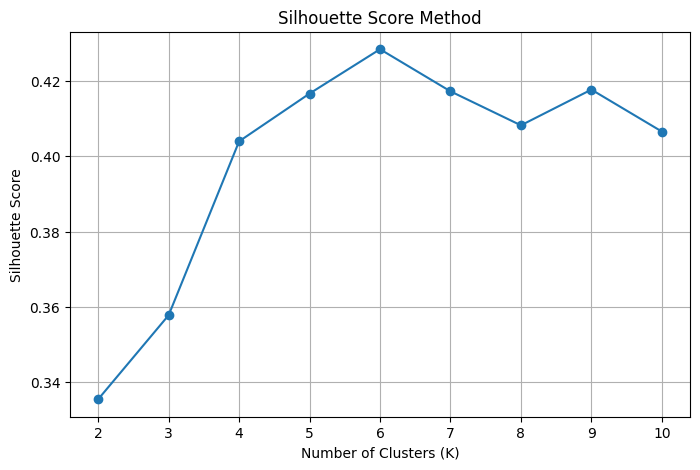

In [50]:
# Import required libraries
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
# Import libraries
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Check different K values
K_range = range(2, 11)
silhouette_scores = []

for k in K_range:

    # Apply K-Means
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_scaled)

    # Calculate Silhouette Score
    score = silhouette_score(
        X_scaled,
        cluster_labels
    )

    silhouette_scores.append(score)
    print(f"K = {k}, Silhouette Score = {score:.3f}")

# Plot the scores
plt.figure(figsize=(8, 5))
plt.plot(K_range, silhouette_scores, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score Method')
plt.xticks(list(K_range))
plt.grid(True)
plt.show()

In [51]:
optimal_k = 5

kmeans = KMeans(
    n_clusters=optimal_k,
    init='k-means++',
    random_state=42
)

cluster_labels = kmeans.fit_predict(scaled_data)

print("K-Means model trained successfully!")

K-Means model trained successfully!


In [52]:
df['Cluster'] = cluster_labels

df.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100),Age_Category,Income_Category,Spending_Category,Age_Group,Cluster
0,1,19,15,39,3,1,1,3,2
1,1,21,15,81,3,1,0,3,2
2,0,20,16,6,3,1,1,3,2
3,0,23,16,77,3,1,0,3,2
4,0,31,17,40,0,1,1,0,4


In [53]:
df['Cluster'].value_counts()

,count
Cluster,
0,50
1,40
2,38
4,36
3,36


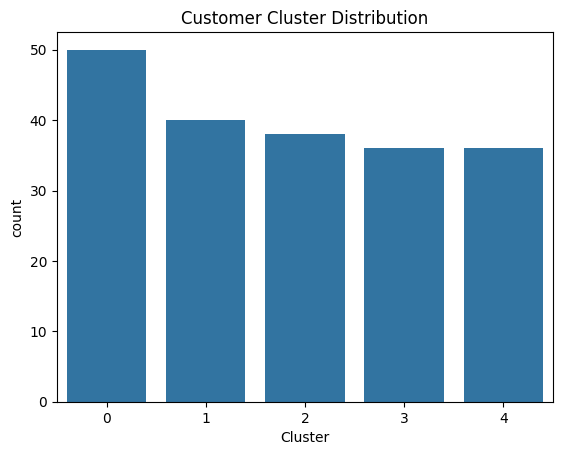

In [54]:
sns.countplot(x=df['Cluster'])

plt.title('Customer Cluster Distribution')

plt.show()

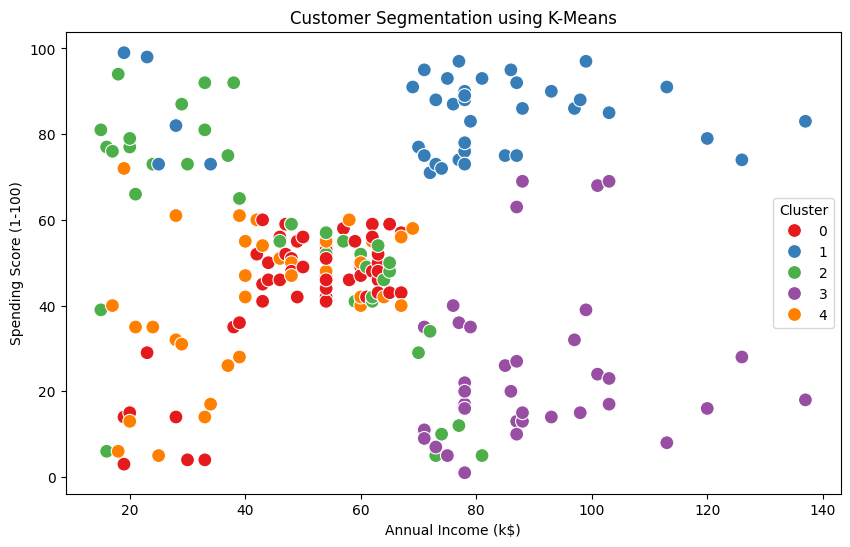

In [55]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x=df['Annual Income (k$)'],
    y=df['Spending Score (1-100)'],
    hue=df['Cluster'],
    palette='Set1',
    s=100
)

plt.title('Customer Segmentation using K-Means')

plt.show()

In [56]:
centroids = kmeans.cluster_centers_

centroids

array([[ 0.12087344,  1.29108275, -0.41375661, -0.25078728,  0.34958143,
         0.9353698 ,  0.82837677,  0.26249718],
       [-0.03021836, -0.4270118 ,  0.67044602,  1.31119821, -0.94754967,
        -0.90650036, -1.40517244, -0.92986289],
       [ 0.06785878, -1.26970383, -0.56780039,  0.18430025,  1.58231595,
         0.32272993, -0.04876604,  1.73959994],
       [ 0.17683337,  0.24799378,  1.12158747, -0.99771411, -0.33424891,
        -1.1663253 , -0.04158929, -0.41080067],
       [-0.38276591, -0.22646378, -0.69252068, -0.30539628, -0.76867028,
         0.53376383,  0.50384397, -0.75684215]])

In [57]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

pca_data = pca.fit_transform(scaled_data)

pca_df = pd.DataFrame(
    pca_data,
    columns=['PCA1', 'PCA2']
)

pca_df['Cluster'] = cluster_labels

pca_df.head()

,PCA1,PCA2,Cluster
0,2.041683,-2.187276,2
1,1.248501,-3.308047,2
2,2.217036,-1.650500,2
3,1.210549,-3.190699,2
4,-0.514241,0.249047,4
